# Matcha — a music recommender you can steer

**The question:** given one track, which other tracks sound like it — and can the
listener decide *how far* from it to travel?

---

## Where we landed

| | |
|---|---|
| **The model** | 518 audio features → PCA (146 components) → nearest neighbours, cosine distance |
| **Held-out `precision@10`** | **0.400** ± 0.006 — **3.2× better than chance** |
| **Genre labels used to recommend** | none. The model matches on sound; genre only marks the paper |
| **The feature** | one dial, familiar → adventurous, with no second model behind it |

---

## How this notebook runs

1. **Load and scale** — 518 audio features for 8,000 tracks
2. **Explore** — what the feature set is made of, and where it misbehaves
3. **Reduce** — PCA, and see the space it produces
4. **Recommend** — the model itself, built twice: by hand, then imported
5. **Measure** — four rulers, because any one of them can be fooled
6. **Validate** — 5-fold, on tracks the pipeline has never seen
7. **Steer** — the Familiar → Adventurous dial, and what it costs

Everything heavy lives in `modeling/`. The cells here call it, so the same code
runs from a notebook, a script, or the command line.

> **Before running:** the MLflow server must be up in its own terminal
> (`make mlflow`). Restart the kernel first if `modeling/` has changed since you
> last ran — Python caches imported modules.


In [1]:
import sys

# make the modeling package importable from inside notebooks/
sys.path.append("..")

import pandas as pd
import numpy as np

from modeling.data import load_fma

# Features (518 audio descriptors) and matching metadata for the 'small' subset
X_small, small_tracks = load_fma(subset="small")

print(f"Data successfully loaded. Shape: {X_small.shape}")

Data successfully loaded. Shape: (8000, 518)


In [2]:
print("small_tracks shape:", small_tracks.shape)
print("X_small shape:", X_small.shape)

small_tracks shape: (8000, 52)
X_small shape: (8000, 518)


In [3]:
from modeling.features import scale_features

X_scaled_df, scaler = scale_features(X_small)
print("Scaled features shape:", X_scaled_df.shape)

Scaled features shape: (8000, 518)


## Exploring the feature set

The 518 columns are not 518 independent facts about a track. They are eleven
families of audio descriptor, each summarised by seven statistics — and the
families are wildly unequal in size.

That matters because PCA picks its directions by variance, and a concept's
variance grows with the number of columns representing it. A family with 84
columns shouts; a family with 7 whispers.

The next two cells look at that imbalance, and at how far the features depart
from the well-behaved, symmetric spread `StandardScaler` assumes.

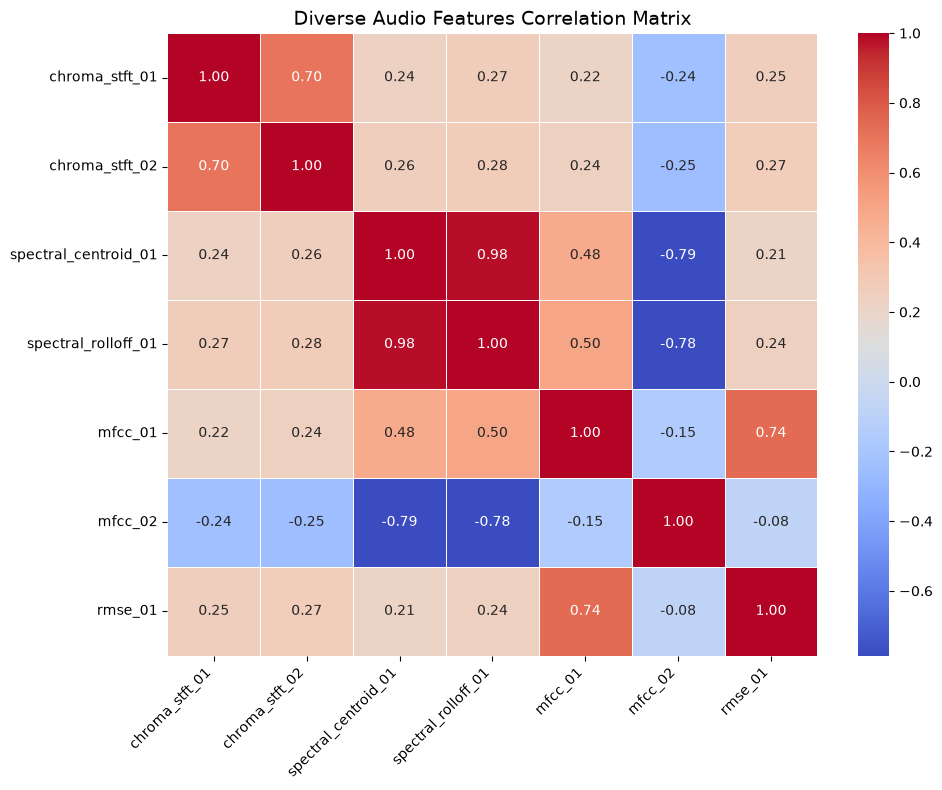

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Explicitly pick 1 feature from each category
target_features = ['chroma_stft', 'spectral_centroid', 'spectral_rolloff', 'mfcc', 'rmse']
selected_cols = []

for feat in target_features:
    matching = [col for col in X_scaled_df.columns if col[0] == feat and col[1] == 'mean']
    if matching:
        selected_cols.extend(matching[:2])  # Take first 2 channels/dimensions of each

df_analysis = X_scaled_df[selected_cols].copy()
df_analysis.columns = [f"{col[0]}_{col[2]}" for col in df_analysis.columns]

# Compute & Plot
plt.figure(figsize=(10, 8))
sns.heatmap(df_analysis.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Diverse Audio Features Correlation Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [5]:
# Two things about the feature set that shape every later decision.
from modeling.evaluation import feature_family_summary, statistic_summary, tail_summary

families = feature_family_summary(X_small)
stats = statistic_summary(X_small)

print("columns per feature family")
print(families.to_string())

chroma = families[families.index.str.startswith("chroma")].sum()
print(f"\nthe three chroma families alone: {chroma} of {X_small.shape[1]} columns "
      f"({chroma / X_small.shape[1]:.0%})")
print("they all measure harmonic content, just by different extraction methods —")
print("so PCA, which picks directions by variance, leans heavily on harmony.")
print(f"meanwhile zcr and rmse (rhythm, texture) get {families['zcr']} columns each.\n")

print("columns per summary statistic")
print(stats.to_string())

tails = tail_summary(X_small, X_scaled_df)
print(f"\ntail heaviness")
print(f"  columns with kurtosis > 100 : {tails['columns_kurtosis_over_100']} of {tails['n_columns']}")
print(f"  max kurtosis                : {tails['max_kurtosis']:.0f}   (a normal distribution is 0)")
print(f"  max |z| after StandardScaler: {tails['max_abs_z']:.1f}   (std deviations from the mean)")
print("\nkurtosis and skew are heavy-tailed by construction, and that is 148 of the 518")
print("columns. RobustScaler is the obvious fix — we tested it and it scored worse")
print("(0.336 vs 0.413), so those outliers carry real signal.")

columns per feature family
mfcc                  140
chroma_cens            84
chroma_cqt             84
chroma_stft            84
spectral_contrast      49
tonnetz                42
rmse                    7
spectral_bandwidth      7
spectral_centroid       7
spectral_rolloff        7
zcr                     7

the three chroma families alone: 252 of 518 columns (49%)
they all measure harmonic content, just by different extraction methods —
so PCA, which picks directions by variance, leans heavily on harmony.
meanwhile zcr and rmse (rhythm, texture) get 7 columns each.

columns per summary statistic
kurtosis    74
max         74
mean        74
median      74
min         74
skew        74
std         74

tail heaviness
  columns with kurtosis > 100 : 86 of 518
  max kurtosis                : 7599   (a normal distribution is 0)
  max |z| after StandardScaler: 88.3   (std deviations from the mean)

kurtosis and skew are heavy-tailed by construction, and that is 148 of the 518
columns. Ro

## Reducing to a feature space

518 dimensions is more than the recommender needs, and distance calculations get
slower and noisier as dimensions pile up.

PCA finds the directions along which tracks differ most and keeps only those. We
ask for **90% of the variance**, which works out at 146 components — the
conventional, defensible default. Not necessarily the optimal one; the tooling
below will tell us.

`N_COMPONENTS` at the top of the next cell is the only knob. `0.90` is a
variance target, `60` would be a fixed component count — the run name, the
artifact filenames and the logged parameters all follow from it.

2026/09/18 14:17:22 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/amintorabi/neuefische_course/Capstone_Project_Repository/capstone-matchas/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


tracking to: http://127.0.0.1:5000/
components needed — 90%: 146, 95%: 207, 99%: 334


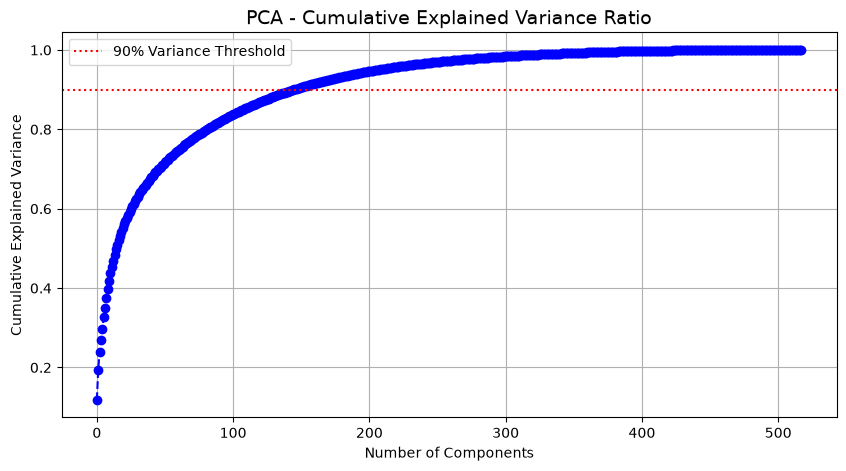

neighbour genre agreement: 0.413  (random = 0.125)


✅ Run logged to MLflow successfully!
   90pct: 146 components, quality 0.413
🏃 View run PCA_90pct at: http://127.0.0.1:5000/#/experiments/4/runs/ea15221583a6432a859f90a6cbd8c1fc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


In [6]:
import matplotlib.pyplot as plt
import mlflow

from modeling.config import TRACKING_URI, MUSIC_EXPERIMENT_NAME
from modeling.data import genre_labels
from modeling.evaluation import neighbour_genre_agreement, random_baseline
from modeling.features import (
    explained_variance_curve,
    components_for_variance,
    fit_pca,
    transform,
    save_artifacts,
    pca_tag,
)

# ⬇️ the only knob. Two forms, both valid:
#      0.90  (float) -> keep enough components for 90% of the variance -> 146
#      60    (int)   -> keep exactly 60 components
#    Run name, artifact names and logged params all follow from it.
N_COMPONENTS = 0.90

# TRACKING_URI comes from .mlflow_uri via modeling/config.py.
# Without set_tracking_uri, MLflow writes to a local store next to the notebook
# and nothing ever shows up in the UI on port 5000.
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(MUSIC_EXPERIMENT_NAME)
print("tracking to:", mlflow.get_tracking_uri())

# 1. Variance curve over all possible components (independent of the target)
cumulative_variance = explained_variance_curve(X_scaled_df)
n_90 = components_for_variance(cumulative_variance, 0.90)
n_95 = components_for_variance(cumulative_variance, 0.95)
n_99 = components_for_variance(cumulative_variance, 0.99)
print(f"components needed — 90%: {n_90}, 95%: {n_95}, 99%: {n_99}")

# 2. Plot Explained Variance
tag = pca_tag(N_COMPONENTS)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cumulative_variance, marker='o', linestyle='--', color='b')
ax.axhline(y=0.90, color='r', linestyle=':', label='90% Variance Threshold')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('PCA - Cumulative Explained Variance Ratio', fontsize=14)
ax.grid(True)
ax.legend()
plt.show()

# 3. Fit at the target size
pca = fit_pca(X_scaled_df, n_components=N_COMPONENTS)

# 4. The metric that actually reflects what the recommender needs:
#    of a track's 10 nearest neighbours, how many share its genre.
#    Explained variance can't tell us this — see modeling/evaluation.py.
labels = genre_labels(small_tracks)
X_pca = transform(X_small, scaler, pca)
quality = neighbour_genre_agreement(X_pca, labels)
print(f"neighbour genre agreement: {quality:.3f}  (random = {random_baseline(labels):.3f})")

with mlflow.start_run(run_name=f"PCA_{tag}"):
    mlflow.log_params({
        "dataset": "fma_small",
        "original_features_count": int(X_scaled_df.shape[1]),
        "n_samples": int(X_scaled_df.shape[0]),
        "scaler": "StandardScaler",
        "pca_target": N_COMPONENTS,
    })
    mlflow.log_metrics({
        "neighbour_genre_agreement": quality,
        "random_baseline": random_baseline(labels),
        "n_components_selected": pca.n_components_,
        "total_explained_variance": float(pca.explained_variance_ratio_.sum()),
        "explained_variance_pc1": float(pca.explained_variance_ratio_[0]),
    })

    mlflow.log_figure(fig, f"pca_cumulative_variance_{tag}.png")

    # suffix keeps e.g. pca_90pct.pkl and pca_60dims.pkl side by side in models/
    scaler_path, pca_path = save_artifacts(scaler, pca, suffix=f"_{tag}")
    mlflow.log_artifact(str(scaler_path))
    mlflow.log_artifact(str(pca_path))

    mlflow.set_tag("stage", "eda-baseline")

    print("✅ Run logged to MLflow successfully!")
    print(f"   {tag}: {pca.n_components_} components, quality {quality:.3f}")

## The baseline recommender

Everything above builds a **feature space** — it reduces 518 audio descriptors to
146 components. That is preprocessing, not a model: nothing so far can take a
track and return anything.

The model is the step that uses that space to answer *"what sounds like this?"*.
The baseline answer is the simplest one available: **the closest tracks by
distance**. No genre filtering, no popularity weighting, no learned similarity —
so that every later idea has something honest to beat.

The next cell does it in four visible steps. The cell after that is the same
thing imported from `modeling/recommender.py`.

In [7]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors

from modeling.features import transform

SEED_TRACK = 2   # AWOL — Food [Hip-Hop]

# ---- step 1: put every track in the PCA space -------------------------------
# scaler.transform then pca.transform, keeping the track ids as the index.
X_pca = transform(X_small, scaler, pca)
print("step 1 — catalogue projected:", X_pca.shape, "(tracks x components)")

# ---- step 2: index the catalogue --------------------------------------------
# cosine compares the *direction* of two feature vectors and ignores their
# magnitude, so a loud track and a quiet one with the same character stay close.
index = NearestNeighbors(metric="cosine").fit(X_pca)
print("step 2 — indexed with cosine distance")

# ---- step 3: look up one track's neighbours ---------------------------------
row = X_pca.index.get_loc(SEED_TRACK)
distances, positions = index.kneighbors(X_pca.iloc[[row]], n_neighbors=11)

# a track is always its own nearest neighbour at distance 0 — drop it
distances, positions = distances[0][1:], positions[0][1:]
neighbour_ids = X_pca.index[positions]
print(f"step 3 — closest tracks to {SEED_TRACK}: {list(neighbour_ids[:3])} ...")

# ---- step 4: attach names so the result is readable -------------------------
meta = small_tracks.loc[neighbour_ids]
recommendations = pd.DataFrame({
    "distance": distances,
    "artist": meta[("artist", "name")].values,
    "title": meta[("track", "title")].values,
    "genre": meta[("track", "genre_top")].values,
}, index=neighbour_ids)

seed = small_tracks.loc[SEED_TRACK]
print(f"\nseed track: {seed[('artist', 'name')]} — {seed[('track', 'title')]} "
      f"[{seed[('track', 'genre_top')]}]\n")
recommendations

step 1 — catalogue projected: (8000, 146) (tracks x components)
step 2 — indexed with cosine distance
step 3 — closest tracks to 2: [7492, 149953, 98584] ...

seed track: AWOL — Food [Hip-Hop]



,distance,artist,title,genre
track_id,,,,
7492,0.423712,BrokeMC,In the Dark,Hip-Hop
149953,0.425256,K. Sparks,Blue Real Talk,Hip-Hop
98584,0.448126,Hi-Rez,Relax (Prod. Joel Johnston),Hip-Hop
115723,0.476600,Martin R.,Acidamine,Electronic
109681,0.478674,CM & Tha Silent Partner,My Place,Hip-Hop
136323,0.481347,D SMILEZ,We Did It! (Fulfillment Tune),Electronic
140134,0.485501,Remain,Acid,Electronic
108031,0.488873,Wann,Happy Birthday,Rock
72477,0.492493,Fhernando,Last Days of Disco,Electronic


In [8]:
# The same four steps, packaged. modeling/recommender.py does exactly what the
# cell above does — this is the version to import elsewhere.
from modeling.recommender import TrackRecommender

rec = TrackRecommender(scaler, pca, metric="cosine").fit(X_small, small_tracks)

print("seed:", rec.describe(SEED_TRACK), "\n")
rec.similar_to(SEED_TRACK, n=10)

seed: AWOL — Food [Hip-Hop] 



,rank,distance,artist,title,genre
track_id,,,,,
7492,1,0.423712,BrokeMC,In the Dark,Hip-Hop
149953,2,0.425256,K. Sparks,Blue Real Talk,Hip-Hop
98584,3,0.448126,Hi-Rez,Relax (Prod. Joel Johnston),Hip-Hop
115723,4,0.476600,Martin R.,Acidamine,Electronic
109681,5,0.478674,CM & Tha Silent Partner,My Place,Hip-Hop
136323,6,0.481347,D SMILEZ,We Did It! (Fulfillment Tune),Electronic
140134,7,0.485501,Remain,Acid,Electronic
108031,8,0.488873,Wann,Happy Birthday,Rock
72477,9,0.492493,Fhernando,Last Days of Disco,Electronic


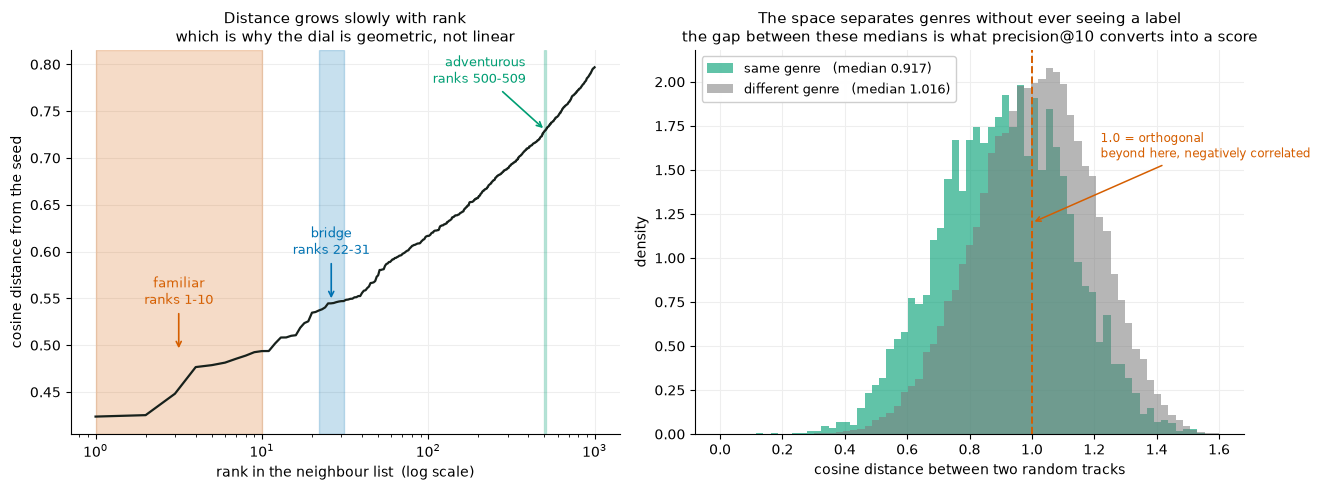

Same-genre pairs sit 0.100 closer in median than different-genre pairs.
The model never reads a genre label — it only measures distance between audio
features. That the two distributions separate at all is the evidence the
feature space carries real musical structure.

The separation is a shift, not a split: the distributions overlap heavily,
which is exactly why precision@10 lands at 0.40 and not 0.95. Genre is a
coarse proxy for what a listener hears.


In [9]:
# Two things worth seeing before trusting the space.
#
# A PC1/PC2 scatter is the obvious plot here and it is the wrong one: those two
# components hold under 20% of the variance, so everything lands in one blob and
# the picture argues against a model that demonstrably works. These two panels
# show what is actually true instead.
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

# ---- left: distance against rank -------------------------------------------
# The curve the whole adventure dial is shaped around.
seed_row = X_pca.index.get_loc(SEED_TRACK)
d_all, _ = index.kneighbors(X_pca.iloc[[seed_row]], n_neighbors=1001)
d_all = d_all[0][1:]
ranks = np.arange(1, len(d_all) + 1)

ax1.plot(ranks, d_all, color="#17211C", lw=1.6)
# The last label is pushed left rather than centred — centred, it runs off the
# right edge of the panel and the rank range gets clipped.
for lo, hi, colour, lbl, dx, ha in [
        (1, 10, "#D55E00", "familiar\nranks 1-10", 0, "center"),
        (22, 31, "#0072B2", "bridge\nranks 22-31", 0, "center"),
        (500, 509, "#009E73", "adventurous\nranks 500-509", -14, "right")]:
    ax1.axvspan(lo, hi, color=colour, alpha=.22)
    ax1.annotate(lbl, xy=(np.sqrt(lo * hi), d_all[hi - 1]), xytext=(dx, 34),
                 textcoords="offset points", ha=ha, fontsize=9, color=colour,
                 arrowprops=dict(arrowstyle="->", color=colour, lw=1.2))

ax1.set_xscale("log")
ax1.set_xlabel("rank in the neighbour list  (log scale)")
ax1.set_ylabel("cosine distance from the seed")
ax1.set_title("Distance grows slowly with rank\nwhich is why the dial is geometric, not linear",
              fontsize=11)
ax1.grid(color="#EEEEEE"); ax1.set_axisbelow(True)
ax1.spines[["top", "right"]].set_visible(False)

# ---- right: does the space know about genre without being told? -------------
# Sample pairs and split them by whether the two tracks share a genre. If the
# distributions sit on top of each other, the space carries no genre signal and
# precision@10 would be luck.
rng = np.random.default_rng(42)
i, j = rng.integers(0, len(X_pca), 40000), rng.integers(0, len(X_pca), 40000)
keep = i != j
i, j = i[keep], j[keep]

V = X_pca.values
num = np.einsum("ij,ij->i", V[i], V[j])
pair_d = 1 - num / (np.linalg.norm(V[i], axis=1) * np.linalg.norm(V[j], axis=1))
same = np.asarray(labels.astype(str))[i] == np.asarray(labels.astype(str))[j]

bins = np.linspace(0, 1.6, 70)
ax2.hist(pair_d[same], bins=bins, color="#009E73", alpha=.62, density=True,
         label=f"same genre   (median {np.median(pair_d[same]):.3f})")
ax2.hist(pair_d[~same], bins=bins, color="#7B7B7B", alpha=.55, density=True,
         label=f"different genre   (median {np.median(pair_d[~same]):.3f})")
ax2.axvline(1.0, color="#D55E00", ls="--", lw=1.4)
ax2.annotate("1.0 = orthogonal\nbeyond here, negatively correlated",
             xy=(1.0, ax2.get_ylim()[1] * .55), xytext=(1.22, ax2.get_ylim()[1] * .72),
             fontsize=8.5, color="#D55E00",
             arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.1))

ax2.set_xlabel("cosine distance between two random tracks")
ax2.set_ylabel("density")
ax2.set_title("The space separates genres without ever seeing a label\n"
              "the gap between these medians is what precision@10 converts into a score",
              fontsize=11)
ax2.legend(fontsize=9.5, framealpha=.95)
ax2.grid(color="#EEEEEE"); ax2.set_axisbelow(True)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

gap = np.median(pair_d[~same]) - np.median(pair_d[same])
print(f"Same-genre pairs sit {gap:.3f} closer in median than different-genre pairs.")
print("The model never reads a genre label — it only measures distance between audio")
print("features. That the two distributions separate at all is the evidence the")
print("feature space carries real musical structure.")
print("\nThe separation is a shift, not a split: the distributions overlap heavily,")
print("which is exactly why precision@10 lands at 0.40 and not 0.95. Genre is a")
print("coarse proxy for what a listener hears.")


## Scoring it — four rulers, because one lies

A single number can always be gamed. Each of these is blind to something the
others catch:

| Ruler | What it asks | What it misses on its own |
|---|---|---|
| `precision@10` | how many of the ten share the seed's genre | treats slot 1 and slot 10 alike |
| `nDCG@10` | are the good ones near the **top** | same hard genre boundary |
| `genre_overlap@10` | how much the full genre lists overlap | ordering |
| `coverage` | how much of the catalogue ever appears | quality — a random model scores well here |

**Why the third one matters for us.** Our product is built on a Familiar →
Adventurous control, and an adventurous recommendation deliberately leaves the
seed's genre. Exact matching scores that as *wrong* — so with only `precision`,
week 2's headline feature would read as a regression the moment it works.
Overlap grades the distance instead, which is how we tell smart exploration from
random noise.

One caveat worth repeating: genre is a **proxy**, not truth. Two tracks can be
similar and carry different labels. These numbers compare configurations
honestly; they do not measure how good the recommender feels to a listener.

In [10]:
# How good is the baseline? Four rulers, because no single one tells the whole story.
from modeling.evaluation import (
    catalogue_coverage,
    genre_overlap_at_k,
    genre_sets,
    ndcg_at_k,
    random_baseline,
)
from modeling.recommender import precision_at_k

K = 10
gsets = genre_sets(small_tracks)   # every genre per track, not just the top one

# 1. precision@k — of the K recommended tracks, how many share the seed's top genre
score = precision_at_k(rec, labels, k=K, sample=None)

# 2. nDCG@k — same idea, but a hit near the top of the list counts for more
ndcg = ndcg_at_k(X_pca, labels, k=K)

# 3. genre overlap — graded instead of right/wrong, so a cross-genre jump to a
#    related genre scores above a jump to an unrelated one. This is the ruler
#    that will still be fair once the Familiar->Adventurous control exists.
overlap = genre_overlap_at_k(X_pca, gsets, k=K)

# 4. coverage — does the recommender surface the catalogue, or the same few tracks?
coverage = catalogue_coverage(X_pca, k=K)

print(f"precision@{K}      : {score:.3f}   (random {random_baseline(labels):.3f}, "
      f"lift {score / random_baseline(labels):.1f}x)")
print(f"nDCG@{K}           : {ndcg:.3f}")
print(f"genre_overlap@{K}  : {overlap:.3f}")
print(f"coverage           : {coverage:.3f}   "
      f"({int(coverage * len(X_pca))} of {len(X_pca)} tracks ever recommended)")

with mlflow.start_run(run_name=f"PCA_{tag}_eval"):
    mlflow.log_params({
        "k": K,
        "metric": "cosine",
        "pca_target": N_COMPONENTS,
        "n_components": int(pca.n_components_),
    })
    mlflow.log_metrics({
        "precision_at_k": score,
        "ndcg_at_k": ndcg,
        "genre_overlap_at_k": overlap,
        "catalogue_coverage": coverage,
        "random_baseline": random_baseline(labels),
    })
    mlflow.set_tag("stage", "baseline-eval")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)

precision@10      : 0.413   (random 0.125, lift 3.3x)
nDCG@10           : 0.433
genre_overlap@10  : 0.274
coverage           : 0.969   (7750 of 8000 tracks ever recommended)

logged to MLflow: ee343a3cb7a44af0bd69f7cbdf8f4f79
🏃 View run PCA_90pct_eval at: http://127.0.0.1:5000/#/experiments/4/runs/ee343a3cb7a44af0bd69f7cbdf8f4f79
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


## Validating on tracks the pipeline has never seen

Everything above fits the scaler and PCA on all 8,000 tracks and then scores
those same tracks. For a fixed catalogue that is defensible, but it cannot
answer the question a reviewer will ask: **does this work for a track the
pipeline has never seen?**

So this is the k-fold version. In each of 5 folds:

- the scaler and PCA are fitted on the training tracks **only**
- the training tracks become the catalogue
- each held-out track is projected into that space and retrieves from it

Note there is no `y_train` / `y_test` here. This model has no target to predict —
it learns nothing from the genre labels, it only measures distance. Genre is
used *after the fact* to check whether the retrieved tracks look sensible. That
is why the split is on `X` alone.

Held-out tracks are not in the catalogue, so unlike the cells above there is no
self-match to drop.

In [11]:
# 5-fold held-out evaluation. Takes a few minutes — PCA is refitted per fold.
# Passing genre_sets_ makes the folds report all four rulers, not just precision,
# so the held-out column lines up one-for-one with the in-sample one above.
from modeling.evaluation import cross_validated_precision

folds = cross_validated_precision(
    X_small, labels,
    n_components=N_COMPONENTS,   # same setting as the baseline above
    metric="cosine",
    k=K,
    n_splits=5,
    genre_sets_=gsets,
)

shown = ["fold", "components", "precision_at_k", "ndcg_at_k", "genre_overlap_at_k", "coverage"]
print(folds[shown].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

in_sample = {
    "precision_at_k": score,
    "ndcg_at_k": ndcg,
    "genre_overlap_at_k": overlap,
    "coverage": coverage,
}

print(f"\n{'metric':22s} {'held-out':>18s}   {'in-sample':>9s}   gap")
for m, insample in in_sample.items():
    mean, spread = folds[m].mean(), folds[m].std()
    print(f"{m:22s} {mean:.3f} +/- {spread:.3f}   {insample:9.3f}   {(insample - mean) / insample:+.1%}")

print("\nCoverage is the one to read differently: held-out, only the 1600 test tracks")
print("query a 6400-track catalogue, so a lower number is expected, not a warning.")

# Log it next to the run from the eval cell, so the baseline carries both protocols.
with mlflow.start_run(run_name=f"PCA_{tag}_kfold"):
    mlflow.log_params({"n_splits": 5, "metric": "cosine", "pca_target": N_COMPONENTS, "k": K})
    for m in in_sample:
        mlflow.log_metric(f"{m}_heldout", folds[m].mean())
        mlflow.log_metric(f"{m}_heldout_std", folds[m].std())
        mlflow.log_metric(f"{m}_insample", in_sample[m])
    mlflow.set_tag("stage", "validation")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)

 fold  components  precision_at_k  ndcg_at_k  genre_overlap_at_k  coverage
    1         143           0.406      0.426               0.270     0.782
    2         144           0.393      0.412               0.255     0.783
    3         143           0.405      0.426               0.267     0.779
    4         144           0.399      0.420               0.262     0.775
    5         144           0.395      0.416               0.256     0.783

metric                           held-out   in-sample   gap
precision_at_k         0.400 +/- 0.006       0.413   +3.2%
ndcg_at_k              0.420 +/- 0.006       0.433   +3.0%
genre_overlap_at_k     0.262 +/- 0.006       0.274   +4.5%
coverage               0.780 +/- 0.004       0.969   +19.4%

Coverage is the one to read differently: held-out, only the 1600 test tracks
query a 6400-track catalogue, so a lower number is expected, not a warning.

logged to MLflow: 5c19c09e79fc44629b18719c63333cee
🏃 View run PCA_90pct_kfold at: http://127.0.0.

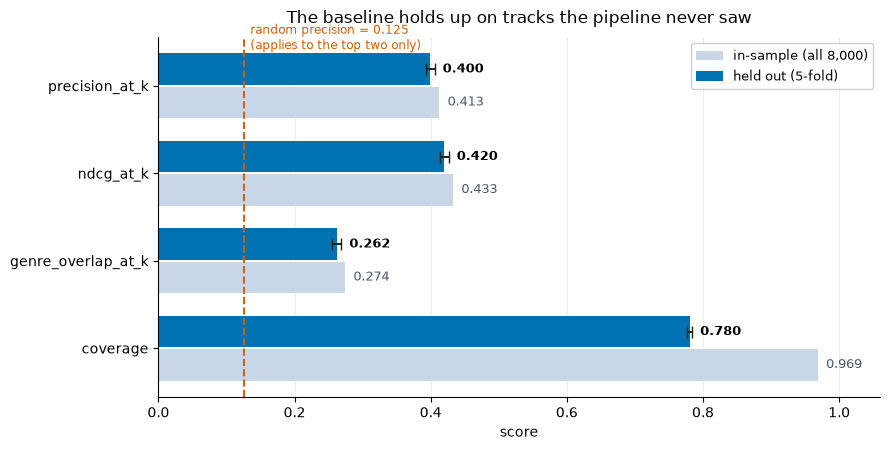

The error bars are the spread across the five folds — all under 0.007, so the
result is stable rather than one lucky split. Every held-out bar sits just
below its in-sample twin, which is the small, expected cost of never having
seen the track. A large gap here would have meant the feature space was
shaped around the tracks it was scored on.


In [12]:
# The scorecard as one picture: held-out against in-sample, with the fold spread.
import matplotlib.pyplot as plt
import numpy as np

names = ["precision_at_k", "ndcg_at_k", "genre_overlap_at_k", "coverage"]
held = [folds[m].mean() for m in names]
err = [folds[m].std() for m in names]
ins = [in_sample[m] for m in names]

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(names))

ax.barh(y + .19, ins, height=.36, color="#C9D6E8", label="in-sample (all 8,000)")
ax.barh(y - .19, held, height=.36, xerr=err, color="#0072B2",
        error_kw=dict(ecolor="#17211C", lw=1.4, capsize=4),
        label="held out (5-fold)")

# The random line is precision's baseline (1 of 8 balanced genres). It is not a
# baseline for coverage or overlap, which are on their own scales — so say so.
ax.axvline(random_baseline(labels), color="#D55E00", ls="--", lw=1.4)
ax.text(random_baseline(labels) + .01, -.72,
        f"random precision = {random_baseline(labels):.3f}\n(applies to the top two only)",
        color="#D55E00", fontsize=8.5, va="top")

for i, (h, s) in enumerate(zip(held, ins)):
    ax.text(h + err[i] + .012, i - .19, f"{h:.3f}", va="center", fontsize=9.5, fontweight="bold")
    ax.text(s + .012, i + .19, f"{s:.3f}", va="center", fontsize=9, color="#4A5B70")

ax.set_yticks(y); ax.set_yticklabels(names, fontsize=10)
ax.set_xlim(0, 1.06); ax.invert_yaxis()
ax.set_xlabel("score")
ax.set_title("The baseline holds up on tracks the pipeline never saw", fontsize=12, pad=10)
# upper right, not lower — the coverage bars reach 0.97 and swallow the box there
ax.legend(loc="upper right", fontsize=9.5, framealpha=.95)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#EEEEEE", zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("The error bars are the spread across the five folds — all under 0.007, so the")
print("result is stable rather than one lucky split. Every held-out bar sits just")
print("below its in-sample twin, which is the small, expected cost of never having")
print("seen the track. A large gap here would have meant the feature space was")
print("shaped around the tracks it was scored on.")


## Familiar → Adventurous

### The problem with being right

Ask the baseline for tracks like a hip-hop seed and it returns:

```
ranks 1-5:   Hip-Hop, Hip-Hop, Hip-Hop, Electronic, Hip-Hop
```

That is a good answer. It is also a useless one after the third time. The
listener already likes hip-hop — we handed back more of what they walked in
with. Every recommender that only ever answers *"the most similar"* ends in the
same place: a closed room.

Now look at ranks 31-35 of the **same** ranked list, same seed:

```
ranks 31-35: International, Rock, Pop, Instrumental, Pop
```

Not one of them is hip-hop. These are discoveries — and they can *never* surface
in a top-10, because thirty hip-hop tracks sit in front of them. If you always
read from position 1, this music is invisible.

**That is why the starting position matters.** Our product is a bridge. A bridge
that never leaves the first ten is just a floor.

### Why not random, then?

Because a random track out of 8,000 is almost certainly unrelated, the listener
dislikes it once, and never trusts the button again.

Rank 200 is a different thing entirely: 7,799 tracks are *less* related than it
is. Still the top 2.5% by similarity. Far away, but **chosen**.

```
rank 1 ──────── rank 30 ──────── rank 500 ──────── random
repetitive      new but related   far but chosen    noise
```

The baseline only ever occupied the far left. The dial lets the listener stand
anywhere on that line.

### How it works — no second model

The model already ranks **all 7,999** other tracks. We just never looked past
the first ten:

```
nearest ──────────────────────────────────────────▶ furthest
[1][2][3][4][5][6][7][8][9][10] [11] ... [500] ... [7999]
└──── what the baseline shows ──┘
```

So the control slides a window of ten down a list that already exists. Nothing
is refitted; only the slice index changes.

`adventure` runs 0 → 1 and maps **geometrically** onto the starting rank —
`500 ** adventure`:

| adventure | starting rank |
|---|---|
| 0.00 | 1 — the baseline, byte for byte |
| 0.25 | 5 |
| 0.50 | 22 |
| 0.75 | 106 |
| 1.00 | 500 |

Geometric rather than linear because distance grows slowly with rank: ranks 1-5
sit at cosine 0.42-0.48, ranks 31-35 at 0.55, ranks 201-205 at 0.66. Ranks 50
and 100 sound alike; ranks 1 and 20 do not. A linear dial would compress the
entire audible range into its first 4% of travel, then do nothing for the rest.
This one moves slowly where the ear notices and fast where it does not.


In [13]:
# The whole mechanism, in the open — before using the packaged version below.
from modeling.recommender import depth_for

# ---- the ranking already exists -------------------------------------------
# One query, deep enough to reach rank 510. The baseline asked for 11 and threw
# the rest away; the list itself is no different.
row = X_pca.index.get_loc(SEED_TRACK)
distances, positions = index.kneighbors(X_pca.iloc[[row]], n_neighbors=511)
distances, positions = distances[0][1:], positions[0][1:]   # drop the seed itself

print(f"the model ranked {len(X_pca) - 1} other tracks; we fetched {len(positions)} of them")
print(f"rank   1 -> distance {distances[0]:.3f}")
print(f"rank  22 -> distance {distances[21]:.3f}")
print(f"rank 500 -> distance {distances[499]:.3f}")
print("\ndistance climbs slowly, which is exactly why the dial is not linear.\n")

# ---- the dial only picks where to start reading ----------------------------
for level, name in [(0.0, "FAMILIAR"), (0.5, "BRIDGE"), (1.0, "ADVENTUROUS")]:
    start = depth_for(level)          # 500 ** level, minus one for 0-based
    window = slice(start, start + 5)  # <- the entire feature, one line

    ids = X_pca.index[positions[window]]
    meta = small_tracks.loc[ids]

    print(f"{name:12s} adventure {level:.1f}  ->  ranks {start + 1}-{start + 5}")
    print(pd.DataFrame({
        "distance": distances[window],
        "artist": meta[("artist", "name")].values,
        "genre": meta[("track", "genre_top")].values,
    }).to_string(index=False, float_format=lambda v: f"{v:.3f}"), "\n")


the model ranked 7999 other tracks; we fetched 510 of them
rank   1 -> distance 0.424
rank  22 -> distance 0.537
rank 500 -> distance 0.729

distance climbs slowly, which is exactly why the dial is not linear.

FAMILIAR     adventure 0.0  ->  ranks 1-5
 distance                  artist      genre
    0.424                 BrokeMC    Hip-Hop
    0.425               K. Sparks    Hip-Hop
    0.448                  Hi-Rez    Hip-Hop
    0.477               Martin R. Electronic
    0.479 CM & Tha Silent Partner    Hip-Hop 

BRIDGE       adventure 0.5  ->  ranks 22-26
 distance       artist        genre
    0.537       Cullah      Hip-Hop
    0.538    Sky Thing Experimental
    0.540 Lee Rosevere Experimental
    0.545  Inox Kapell Experimental
    0.545         Skip   Electronic 

ADVENTUROUS  adventure 1.0  ->  ranks 500-504
 distance                            artist        genre
    0.729               Height With Friends      Hip-Hop
    0.729                           Pharaos         R

In [14]:
# The same thing, packaged: modeling/recommender.py does exactly the cell above.
# `adventure` defaults to 0.0, so every existing call behaves as it always did.
rec.similar_to(SEED_TRACK, n=5, adventure=0.75)


,rank,distance,artist,title,genre
track_id,,,,,
80773,106,0.620257,Zlatni Makedoncinja,Pajdusko,International
1083,107,0.620352,Magic Lantern,Feasting on Energy,Experimental
94415,108,0.621630,Kakurenbo,Somatou,Electronic
148028,109,0.622137,BoyHoodBuchi,Disco From The Clouds,Hip-Hop
75371,110,0.622370,Kellee Maize,In Tune,Hip-Hop


In [15]:
# Try any track. Change TRY_TRACK and re-run.
#
# A useful move: take one of the ten below and put ITS id here. Each step lands
# somewhere new, which is a second route to discovery alongside the dial — and
# unlike the dial, the listener can see the path they took.
TRY_TRACK = 109681        # CM & Tha Silent Partner — which was rank 5 of SEED_TRACK

print("seed:", rec.describe(TRY_TRACK), "\n")
picks = rec.similar_to(TRY_TRACK, n=10)
print(picks.to_string(float_format=lambda v: f"{v:.3f}"))

seed_genre = str(rec.tracks_.loc[TRY_TRACK, ("track", "genre_top")])
shared = len(set(rec.similar_to(SEED_TRACK, n=10).index) & set(picks.index))
print(f"\nsame genre as this seed          : {(picks['genre'] == seed_genre).sum()} of 10")
print(f"also in track {SEED_TRACK}'s top ten        : {shared} of 10")
print("Few shared tracks is the good outcome — it means a step actually moves you.")


seed: CM & Tha Silent Partner — My Place [Hip-Hop] 

          rank  distance               artist                                                    title         genre
track_id                                                                                                            
96675        1     0.371         Deadly Combo                                         Can I Get A Clap       Hip-Hop
72477        2     0.387            Fhernando                                       Last Days of Disco    Electronic
78850        3     0.413                Stray                                      Kamehameha (c/ J-K)       Hip-Hop
38878        4     0.422          Anders Ilar                                                Traveller    Electronic
144172       5     0.427                  J-K                                              Henna Negra       Hip-Hop
64331        6     0.446               Pierlo                       Promo Mix Vocal Edit (Luv Dub Mix)    Electronic
148302     

In [16]:
# One thing about that step which is worth knowing before designing the UI.
import numpy as np

def rank_and_distance(seed, target):
    """Where `target` sits in `seed`'s ranked neighbour list, and how far away."""
    row = rec.embedding_.iloc[[rec._position(seed)]]
    d, p = rec.index_.kneighbors(row, n_neighbors=len(rec.track_ids_))
    pos = int(np.flatnonzero(rec.track_ids_[p[0]] == target)[0])
    return pos, d[0][pos]      # pos counts from 0, and index 0 is the seed itself

fwd_rank, fwd_d = rank_and_distance(SEED_TRACK, TRY_TRACK)
bwd_rank, bwd_d = rank_and_distance(TRY_TRACK, SEED_TRACK)

print(f"{SEED_TRACK} -> {TRY_TRACK}:  rank {fwd_rank:4d}   distance {fwd_d:.4f}")
print(f"{TRY_TRACK} -> {SEED_TRACK}:  rank {bwd_rank:4d}   distance {bwd_d:.4f}")

print("\nThe distance is identical — cosine is symmetric, it has to be. The ranks")
print("are not, and that is not a bug: rank means 'how many tracks are closer',")
print("which depends on how crowded each track's own neighbourhood is. A track in")
print("a dense region pushes everything else down its list.")
print("\nSo 'A is similar to B' does not imply 'B is similar to A' — worth knowing")
print("before promising a back button that retraces the path.")


2 -> 109681:  rank    5   distance 0.4787
109681 -> 2:  rank   20   distance 0.4787

The distance is identical — cosine is symmetric, it has to be. The ranks
are not, and that is not a bug: rank means 'how many tracks are closer',
which depends on how crowded each track's own neighbourhood is. A track in
a dense region pushes everything else down its list.

So 'A is similar to B' does not imply 'B is similar to A' — worth knowing
before promising a back button that retraces the path.


### What does it cost — and which ruler can even tell?

One seed track is an anecdote. The cell above happens to look good; it would
look good even if the feature were broken, because we chose the seed.

But before measuring, notice a problem with the rulers we have. **Three of the
four scorecard metrics are built on genre**, and two of those ask the same
question:

| Metric | Built on | Judges |
|---|---|---|
| `precision@10` | genre, hard — `genre_top`, right or wrong | familiarity |
| `nDCG@10` | genre, hard + position | familiarity, ordering |
| `genre_overlap@10` | genre, **graded** — `genres_all`, Jaccard | how far a jump landed |
| `coverage` | no genre at all | catalogue breadth, **system-wide** |

`genre_overlap` is the only genre metric that treats an adventurous
recommendation fairly, which is why it was frozen into the scorecard before this
feature existed.

**The hole:** not one of the four notices when a single listener's ten tracks
are near-copies of each other. `coverage` cannot — it counts what the whole
catalogue surfaces across *every* seed, so a recommender can reach 68% of the
catalogue while handing each individual listener ten interchangeable tracks. Ten
tracks by the same artist would score a perfect `precision@10`.

For a feature named *adventurous*, that is the wrong blind spot to keep. So two
metrics are added alongside — neither touches genre:

- **`intra_list_diversity`** — mean distance between the ten recommendations
  *themselves*, not to the seed. The per-listener version of coverage.
- **`novelty`** — mean distance from the seed. Trivially gamed on its own
  (recommend the furthest tracks and it maxes out), so read it against
  `precision`, which that strategy destroys.

The original four stay **frozen** — every comparison in this notebook rests on
them. These are additions, not replacements.

**What the next cell has to show.** `precision` and `genre_overlap` should
*fall* — that is the feature working, not a regression. `novelty`,
`intra_list_diversity` and `coverage` should *rise*. A dial that moved neither
set would be decoration. Beyond that, three decisions:

1. **Is there a cliff?** A depth where relevance collapses would mean capping
   the dial before it.
2. **Where does the far end land?** At random (0.125) we built a shuffle button
   and should say so.
3. **Does `genre_overlap` hold up better than exact matching?** That would mean
   the far recommendations are still musically related, not merely distant.


In [17]:
# 1,000 seeds, five depths, six rulers.
from modeling.evaluation import depth_profile

profile = depth_profile(X_pca, labels, genre_sets_=gsets, k=K, sample=1000)

shown = ["adventure", "depth", "novelty", "precision_at_k", "genre_overlap_at_k",
         "intra_list_diversity", "coverage"]
print(profile[shown].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

rnd = random_baseline(labels)
near, far = profile.iloc[0], profile.iloc[-1]

print("\n--- direction of travel ---")
for m in ["precision_at_k", "genre_overlap_at_k", "novelty", "intra_list_diversity", "coverage"]:
    arrow = "down" if far[m] < near[m] else "UP  "
    print(f"{m:22s} {near[m]:.3f} -> {far[m]:.3f}   {arrow} {(far[m] - near[m]) / near[m]:+6.0%}")

print("\n--- reading it ---")
print(f"1. no cliff: precision falls {near.precision_at_k:.3f} -> {far.precision_at_k:.3f} "
      f"in even steps, so a continuous slider needs no safety cap.")
print(f"2. the far end is {far.precision_at_k:.3f}, still {far.precision_at_k / rnd:.1f}x "
      f"random ({rnd:.3f}). Steering, not shuffling.")
print(f"3. intra_list_diversity moves furthest of the three that rise "
      f"({(far.intra_list_diversity - near.intra_list_diversity) / near.intra_list_diversity:+.0%}).")
print("   That is variety as one listener experiences it. Coverage barely notices")
print("   because it is a system-wide count, which is exactly the blind spot the")
print("   new metric was added to cover.")

# Logged with step=depth, so MLflow draws these as curves rather than five runs.
with mlflow.start_run(run_name=f"PCA_{tag}_adventure"):
    mlflow.log_params({"k": K, "metric": "cosine", "max_depth": 499, "sample": 1000})
    for r in profile.itertuples():
        for m in ["novelty", "precision_at_k", "genre_overlap_at_k",
                  "intra_list_diversity", "coverage"]:
            mlflow.log_metric(f"{m}_by_depth", getattr(r, m), step=r.depth)
    mlflow.set_tag("stage", "adventure-control")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)


 adventure  depth  novelty  precision_at_k  genre_overlap_at_k  intra_list_diversity  coverage
     0.000      0    0.412           0.406               0.269                 0.508     0.603
     0.220      3    0.438           0.374               0.233                 0.533     0.601
     0.500     21    0.494           0.316               0.184                 0.598     0.610
     0.750    105    0.575           0.270               0.151                 0.688     0.643
     1.000    499    0.692           0.214               0.113                 0.808     0.683

--- direction of travel ---
precision_at_k         0.406 -> 0.214   down   -47%
genre_overlap_at_k     0.269 -> 0.113   down   -58%
novelty                0.412 -> 0.692   UP     +68%
intra_list_diversity   0.508 -> 0.808   UP     +59%
coverage               0.603 -> 0.683   UP     +13%

--- reading it ---
1. no cliff: precision falls 0.406 -> 0.214 in even steps, so a continuous slider needs no safety cap.
2. the far end is 


logged to MLflow: 069691b3704c4bb2a6d61f08a28a7242
🏃 View run PCA_90pct_adventure at: http://127.0.0.1:5000/#/experiments/4/runs/069691b3704c4bb2a6d61f08a28a7242
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


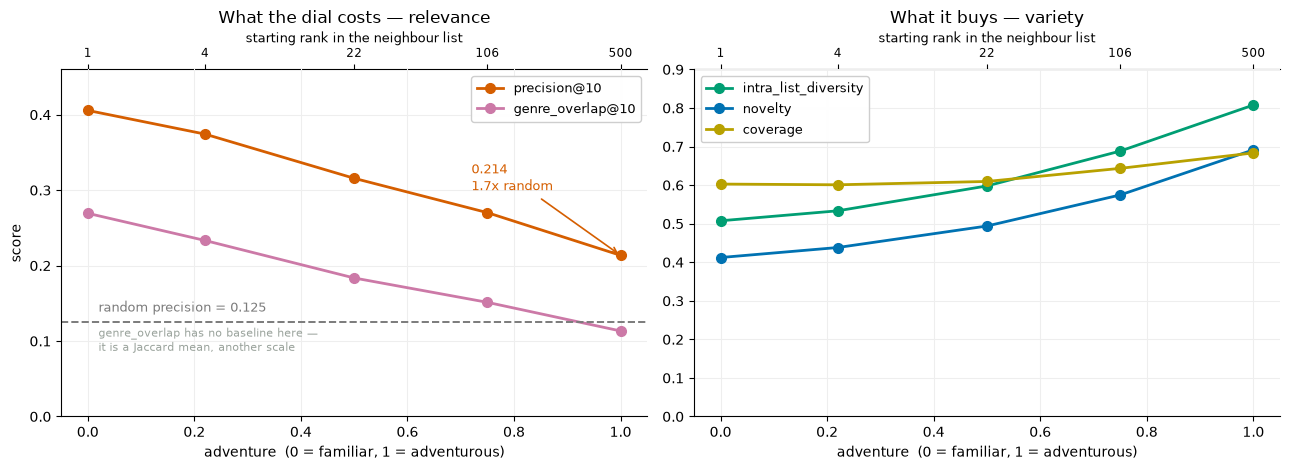

Left panel: both genre metrics fall smoothly — no cliff, so the slider can be
continuous. The far end stays clear of the random line, which is the whole
claim: this is steering, not shuffling.

Right panel: intra_list_diversity climbs fastest. That is the variety one
listener actually hears. Coverage is nearly flat because it is a system-wide
count — the exact blind spot intra_list_diversity was added to cover.


In [18]:
# The dial as one picture. Two panels, because the metrics pull in two directions.
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
a = profile["adventure"]

# ---- left: what it costs ----------------------------------------------------
for m, colour, lbl in [("precision_at_k", "#D55E00", "precision@10"),
                       ("genre_overlap_at_k", "#CC79A7", "genre_overlap@10")]:
    ax1.plot(a, profile[m], "o-", color=colour, lw=2, ms=7, label=lbl)

rnd = random_baseline(labels)
# precision's baseline only — genre_overlap is a Jaccard mean on its own scale,
# so it dipping under this line means nothing and the label has to say that.
ax1.axhline(rnd, color="#7B7B7B", ls="--", lw=1.4)
ax1.text(.02, rnd + .014, f"random precision = {rnd:.3f}", color="#7B7B7B", fontsize=9)
ax1.text(.02, rnd - .038, "genre_overlap has no baseline here —\nit is a Jaccard mean, another scale",
         color="#9AA39C", fontsize=8)
ax1.annotate(f"{profile.precision_at_k.iloc[-1]:.3f}\n{profile.precision_at_k.iloc[-1]/rnd:.1f}x random",
             xy=(1, profile.precision_at_k.iloc[-1]), xytext=(.72, .30),
             fontsize=9.5, color="#D55E00",
             arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.2))
ax1.set_title("What the dial costs — relevance", fontsize=12)
ax1.set_ylim(0, .46)

# ---- right: what it buys ----------------------------------------------------
for m, colour, lbl in [("intra_list_diversity", "#009E73", "intra_list_diversity"),
                       ("novelty", "#0072B2", "novelty"),
                       ("coverage", "#B8A100", "coverage")]:
    ax2.plot(a, profile[m], "o-", color=colour, lw=2, ms=7, label=lbl)
ax2.set_title("What it buys — variety", fontsize=12)
ax2.set_ylim(0, .9)

for ax, ranks in [(ax1, True), (ax2, True)]:
    ax.set_xlabel("adventure  (0 = familiar, 1 = adventurous)")
    ax.legend(fontsize=9.5, framealpha=.95)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#EEEEEE"); ax.set_axisbelow(True)
    if ranks:
        top = ax.secondary_xaxis("top")
        top.set_xticks(a); top.set_xticklabels(profile["depth"] + 1, fontsize=8.5)
        top.set_xlabel("starting rank in the neighbour list", fontsize=9)

ax1.set_ylabel("score")
plt.tight_layout()
plt.show()

print("Left panel: both genre metrics fall smoothly — no cliff, so the slider can be")
print("continuous. The far end stays clear of the random line, which is the whole")
print("claim: this is steering, not shuffling.")
print("\nRight panel: intra_list_diversity climbs fastest. That is the variety one")
print("listener actually hears. Coverage is nearly flat because it is a system-wide")
print("count — the exact blind spot intra_list_diversity was added to cover.")
